# Tests de validation MSUC

Ce notebook entraine la politique SDDP sur une instance puis la simule. On choisit l'instance,
l'horizon, le nombre de scenarios, la formulation (3-bin ou intervalle) et les reglages de `train`
(nombre d'iterations, ecart d'optimalite du MIP racine), puis on regarde la trajectoire de la borne
inferieure, le cout de la politique simulee et la repartition du temps de calcul.

Les verifications rigoureuses (borne <= optimum exact <= politique, equivalence des formulations
3-bin et intervalle, Prop. 3) sont dans `examples/toy_convergence.jl` et `examples/compare_formulations.jl`.

A executer depuis la racine du depot (le kernel Julia active automatiquement ce projet).

## 1. Installation des dependances (une seule fois)

Installe les paquets listes dans `Project.toml` (JuMP, Gurobi.jl, CSV, DataFrames, NCDatasets, ...). 
Necessite une licence Gurobi valide sur la machine.

In [1]:
import Pkg
Pkg.activate(@__DIR__)  # active ce projet, quel que soit le kernel Julia choisi
Pkg.instantiate()

  Activating project at `~/Documents/MSUC`


In [2]:
using MSUC, Gurobi, Printf, Random

GRB_ENV = Gurobi.Env()
optimizer = () -> Gurobi.Optimizer(GRB_ENV)

Set parameter Username
Set parameter LicenseID to value 2818369
Academic license - for non-commercial use only - expires 2027-05-05


#2 (generic function with 1 method)

In [ ]:
INSTANCE    = "Data/T-Ramp/50_0_5_w.nc4"  # chemin vers le fichier .nc4
T           = 24                           # horizon (nombre de pas de temps)
S           = 1                            # nombre de scenarios (support de l'innovation ARMA)
SIGMA       = 1.0                          # amplitude de l'alea : multiplie l'ecart-type de l'innovation ARMA (0.0 = deterministe)
ITERATIONS  = 20                          # nombre d'iterations SDDP
MIP_GAP     = 1e-3                         # ecart d'optimalite du MIP racine : 1e-2 = 1 %, 1e-3 = 0.1 %, nothing = defaut du solveur (1e-4)
PASSES_PER_MIP = 1                         # passes avant/arriere (LP) par resolution du MIP racine : 1 = usuel, 5 ou 10 = plus de coupes entre deux MIP ; ITERATIONS compte alors des cycles
PRINT_LEVEL = 1                            # 0 = silencieux, 1 = log complet de MSUC.train

# :threebin  -> formulation 3-bin  (Sect. 2 de l'article, coupes (12))
# :extended  -> formulation intervalle (Sect. 3 de l'article, coupes (41))
METHOD = :extended

:extended

In [20]:
FORMULATIONS = Dict(
    :threebin => (MSUC.subproblem_builder_UC_def,     MSUC.SDDPFormulation,     "3-bin"),
    :extended => (MSUC.subproblem_builder_UC_extended, MSUC.ExtendedFormulation, "intervalle"),
)
builder, method, label = FORMULATIONS[METHOD]

instance = MSUC.parse_nc4(INSTANCE, optimizer, T; S = S, sigma = SIGMA)
@printf("instance %s : %d unites, %d intervalles, T = %d, S = %d, methode = %s\n",
        basename(INSTANCE), instance.N,
        sum(length(u.intervals) for u in instance.Thermalunits), T, S, label)

instance 50_0_5_w.nc4 : 50 unites, 11650 intervalles, T = 24, S = 1, methode = intervalle


In [21]:
model = MSUC.PolicyGraph(
    builder, instance, 1.0, MSUC.Graph(T + 1), method;   # force = 1 : l'amplitude de l'alea est donnee par SIGMA
    lower_bound = 0.0, optimizer = optimizer,
)

# Garde, sans toucher a l'algorithme, le planning x^k et les etats echantillonnes de chaque iteration
# (memes enregistrements que `train_job` de runSMS.jl)
record, record_pass, _, schedules, states = MSUC.make_recorder(model)

Random.seed!(MSUC.SEED)   # meme graine que `train_job` (runSMS.jl) : les runs sont reproductibles
MSUC.train(model; iteration_limit = ITERATIONS, mip_gap = MIP_GAP,
            passes_per_mip = PASSES_PER_MIP, print_level = PRINT_LEVEL,
            forward_pass_callback = record_pass, post_iteration_callback = record)

-------------------------------------------------------------------
         MSUC.jl (c) Oscar Dowson and contributors, 2017-25
-------------------------------------------------------------------
problem
  nodes           : 25
  state variables : 52
  scenarios       : 1.00000e+00
  existing cuts   : false
subproblem structure
  VariableRef                             : [359, 15405]
  AffExpr in MOI.EqualTo{Float64}         : [3, 4973]
  AffExpr in MOI.GreaterThan{Float64}     : [1, 51]
  AffExpr in MOI.LessThan{Float64}        : [200, 4800]
  VariableRef in MOI.EqualTo{Float64}     : [1, 1]
  VariableRef in MOI.GreaterThan{Float64} : [52, 11700]
  VariableRef in MOI.LessThan{Float64}    : [50, 50]
  VariableRef in MOI.Parameter{Float64}   : [250, 250]
  VariableRef in MOI.ZeroOne              : [3650, 3650]
numerical stability report
  matrix range     [1e-01, 8e+03]
  objective range  [1e+00, 4e+03]
  bounds range     [1e+02, 3e+02]
  rhs range        [1e+00, 8e+03]
-----------------

### Resultats : trajectoire de la borne et cout de la politique simulee

it   1   borne = 194403.68   incumbent = 194403.68
it   2   borne = 1912335.26   incumbent = 1913179.49
it   3   borne = 1983017.62   incumbent = 1984885.71
it   4   borne = 4449591.92   incumbent = 4451708.05
it   5   borne = 4503963.84   incumbent = 4506222.84
it   6   borne = 5563653.40   incumbent = 5565605.10
it   7   borne = 9167595.56   incumbent = 9175537.16
it   8   borne = 9242618.34   incumbent = 9245982.03
it   9   borne = 9248199.76   incumbent = 9254590.08
it  10   borne = 9273820.23   incumbent = 9276384.88
it  11   borne = 9311324.92   incumbent = 9318062.84
it  12   borne = 9311324.92   incumbent = 9319989.20
it  13   borne = 9316183.79   incumbent = 9323588.71
it  14   borne = 9316813.95   incumbent = 9320774.50
it  15   borne = 9317037.06   incumbent = 9324603.44
it  16   borne = 9318576.99   incumbent = 9323564.82
it  17   borne = 9371904.45   incumbent = 9376452.77
it  18   borne = 9377850.62   incumbent = 9385412.39
it  19   borne = 9378208.75   incumbent = 938313

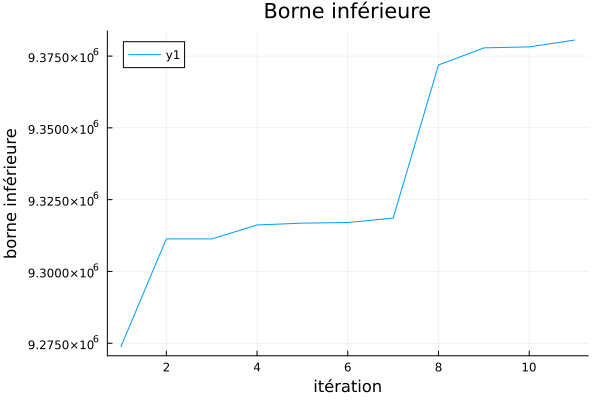

In [6]:
using Plots
log = model.most_recent_training_results.log
for l in log
    @printf("it %3d   borne = %.2f   incumbent = %.2f\n", l.iteration, l.bound, l.incumbent)
end
plot([l.bound for l in log if l.iteration >= 10], title = "Borne inférieure", xlabel = "itération", ylabel = "borne inférieure")

In [7]:
t_sim = @elapsed sim = MSUC.simulate(model; seed = MSUC.SEED)   # meme graine que `simulate_job` (runSMS.jl)
@printf("\ncout de la politique simulee = %.2f  (%d chemins, exhaustif = %s, %.1f s)\n",
        sim.cost, sim.npaths, sim.exhaustive, t_sim)
@printf("intervalle de confiance a 95 %% : [%.2f, %.2f]  (erreur standard %.2f)\n",
        sim.ci95[1], sim.ci95[2], sim.stderr)
@printf("borne finale = %.2f  ->  encadrement relatif = %.2e\n",
        log[end].bound, 100*(sim.cost - log[end].bound) / abs(log[end].bound))


cout de la politique simulee = 10155978.15  (1 chemins, exhaustif = true, 3.8 s)
intervalle de confiance a 95 % : [10155978.15, 10155978.15]  (erreur standard 0.00)
borne finale = 9380575.68  ->  encadrement relatif = 8.27e+00


### Diagnostic : intervalles choisis et etats echantillonnes

`schedules[k]` est le planning x^k choisi par le MIP racine a l'iteration k (en formulation intervalle,
ses intervalles sont dans `selected`) et `states[k][p]` la trajectoire de la passe avant p de l'iteration k :
`sampled_states_power[n]` et `sampled_states_zeta[n]` sont l'etat (production y, etat d'incertitude zeta) a la
sortie du noeud n ; le noeud 1 est l'etat initial et le noeud n l'etat a la fin du pas n-1.

La premiere cellule resume toutes les iterations (borne, incumbent, planning nouveau ou deja vu, variation des
etats echantillonnes) ; la seconde detaille une iteration en la comparant a la precedente ; la troisieme compare
y^k a y(gamma^k, ytilde^{k-1}) = somme, sur les intervalles choisis a l'iteration k, des points de linearisation
ytilde^{k-1}_{a,b,t} des coupes de l'iteration k-1 (la production visitee a l'iteration k-1 si l'intervalle y etait
deja choisi ou atteignable depuis un intervalle choisi, la production maximale atteignable ybar sinon) : c'est la production que ces coupes « attendent » pour le planning gamma^k. Un
ecart signifie que la coupe est evaluee en un autre point que celui ou elle a ete linearisee.

In [8]:
# Intervalles (unite, a, b) du planning x^k : l'unite est allumee aux pas a, ..., b-1 (b = T+1 : jusqu'a la fin
# de l'horizon ; a <= 0 : intervalle initial, l'unite est deja allumee au depart).
function intervalles(k)
    s, I = schedules[k], instance.intervals
    isempty(s.selected) || return [(I.unit[id], I.a[id], I.b[id]) for id in s.selected]
    # 3-bin : aucun intervalle n'est choisi, on relit les periodes de marche de u (colonne t+1 = pas t)
    out = Tuple{Int,Int,Int}[]
    for i in 1:instance.N
        t = 0
        while t <= T
            if s.u[i, t+1] > 0.5
                a = t
                while t < T && s.u[i, t+2] > 0.5
                    t += 1
                end
                push!(out, (i, a, t + 1))
            end
            t += 1
        end
    end
    return out
end

# Intervalles de l'iteration k, unite par unite
function par_unite(k)
    d = [Tuple{Int,Int}[] for _ in 1:instance.N]
    for (i, a, b) in intervalles(k)
        push!(d[i], (a, b))
    end
    return sort!.(d)
end

# Production y (unites x noeuds) le long de la passe avant p de l'iteration k
production(k, p = 1) = reduce(hcat, states[k][p].sampled_states_power)

# y(gamma^k, ytilde^{k-1}) = somme des gamma^k_{a,b} ytilde^{k-1}_{a,b,t} : la production que les coupes de
# l'iteration k-1 « attendent » quand le planning est gamma^k. ytilde^{k-1}_{a,b,t} est le point ou la coupe de
# l'iteration k-1 a ete linearisee pour l'intervalle [a, b] : la production visitee y^{k-1}_t si l'intervalle
# etait deja choisi a l'iteration k-1 ou atteignable depuis un intervalle choisi, la production maximale atteignable ybar sinon. Seuls les intervalles actifs au pas t+1 portent un
# terme en y_t dans la coupe ; ailleurs la coupe ne depend pas de y_t et `attendu` vaut NaN. Colonne n = noeud n
# = pas n-1. `nouveau[i, n]` : l'intervalle n'etait pas choisi a l'iteration k-1.
function y_gamma(k)
    I = instance.intervals
    visite = production(k - 1, length(states[k-1]))    # derniere passe de l'iteration k-1 : la coupe la plus recente
    deja = Set(schedules[k-1].selected)
    choisis = [Tuple{Int,Int}[] for _ in 1:instance.N]    # intervalles choisis de chaque unite a l'iteration k-1
    for id in schedules[k-1].selected
        push!(choisis[I.unit[id]], (I.a[id], I.b[id]))
    end
    attendu = fill(NaN, instance.N, T + 1)
    nouveau = falses(instance.N, T + 1)
    for id in schedules[k].selected
        i, a, b = I.unit[id], I.a[id], I.b[id]
        for t in 0:(T-1)
            MSUC.is_on_interval(a, b, t + 1) || continue
            y = visite[i, t+1]
            attendu[i, t+1] = MSUC.linearization_point(instance.Thermalunits[i], a, b, t, T, y, id in deja, choisis[i])
            nouveau[i, t+1] = !(id in deja)
        end
    end
    return attendu, nouveau
end

# Plus grand ecart en valeur absolue, sans compter les NaN
max_abs(M) = maximum(abs, filter(!isnan, M); init = 0.0)

K = length(log)
@printf("%4s %12s %12s %10s %6s %9s %10s %10s  %s\n",
        "it", "borne", "incumbent", "ecart rel.", "#int.", "#changees", "max|dy|", "max|y-yg|", "planning")
for k in 1:K
    changees = k == 1 ? "-" : string(count(par_unite(k) .!= par_unite(k - 1)))   # unites dont les intervalles different de k-1
    dy = k == 1 ? "-" : @sprintf("%.3g", maximum(abs, production(k) .- production(k - 1)))
    dyg = METHOD == :extended && k >= 2 ? @sprintf("%.3g", max_abs(production(k) .- y_gamma(k)[1])) : "-"   # y^k - y(gamma^k, ytilde^{k-1})
    vu = findfirst(j -> schedules[j].x == schedules[k].x, 1:k-1)
    @printf("%4d %12.2f %12.2f %10.2e %6d %9s %10s %10s  %s\n",
            k, log[k].bound, log[k].incumbent, (log[k].incumbent - log[k].bound) / abs(log[k].incumbent),
            length(intervalles(k)), changees, dy, dyg, vu === nothing ? "nouveau" : "identique a l'iteration $vu")
end

  it        borne    incumbent ecart rel.  #int. #changees    max|dy|  max|y-yg|  planning
   1    194403.68    194403.68   5.99e-16     27         -          -          -  nouveau
   2   1912335.26   1913179.49   4.41e-04     43        41        323        245  nouveau
   3   1983017.62   1984885.71   9.41e-04     48        27        292        245  nouveau
   4   4449591.92   4451708.05   4.75e-04     56        30        292        218  nouveau
   5   4503963.84   4506222.84   5.01e-04     53         8        245        245  nouveau
   6   5563653.40   5565605.10   3.51e-04     69        27        253        245  nouveau
   7   9167595.56   9175537.16   8.66e-04     47        39        245        245  nouveau
   8   9242618.34   9245982.03   3.64e-04     50        14        287        245  nouveau
   9   9248199.76   9254590.08   6.91e-04     48         5        287        215  nouveau
  10   9273820.23   9276384.88   2.76e-04     48         8        287        205  nouveau
  11   93

Intervalles de l'iteration 20 ; * : unites qui different de l'iteration 19

   unite   1 : [1, 25]
   unite   2 : [1, 2] [6, 25]
   unite   3 : [1, 2] [7, 25]
   unite   4 : [-1, 25]
   unite   5 : [-2, 25]
 * unite   6 : [1, 2] [4, 25]  ->  [1, 2] [6, 25]
   unite   7 : [0, 25]
   unite   8 : [0, 25]
   unite   9 : [1, 25]
   unite  10 : [0, 25]
   unite  11 : [0, 25]
 * unite  12 : [0, 25]  ->  [0, 5] [7, 25]
   unite  13 : [-3, 25]
   unite  14 : [1, 2] [7, 25]
   unite  15 : [1, 25]
   unite  16 : [1, 25]
   unite  17 : [0, 25]
 * unite  18 : [1, 2] [7, 25]  ->  [1, 2] [4, 25]
   unite  19 : [-3, 25]
   unite  20 : [1, 2] [7, 25]
   unite  21 : [1, 25]
   unite  22 : [1, 2] [6, 25]
   unite  23 : [-2, 25]
   unite  24 : [0, 25]
 * unite  25 : [1, 2] [6, 25]  ->  [1, 2] [7, 25]
   unite  26 : [8, 25]
 * unite  27 : eteinte  ->  [8, 16]
 * unite  28 : [8, 18]  ->  [8, 16]
 * unite  29 : [-7, 16]  ->  [-7, 5]
   unite  30 : [-4, 4]
   unite  32 : [-5, 25]
   unite  33 : [-5, 24]
   un

2×25 Matrix{Float64}:
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0     0.0  0.0  0.0  0.0  0.0  0.0  0.0


Unites dont la production y differe d'au moins 1e-6 de celle de l'iteration 19 :
   unite   6 : ecart max   67.298 au noeud  7  (y = 31.000 contre 98.298)
   unite  12 : ecart max  121.000 au noeud  6  (y = 0.000 contre 121.000)
   unite  17 : ecart max   27.413 au noeud  4  (y = 82.587 contre 110.000)
   unite  18 : ecart max   98.286 au noeud  7  (y = 98.286 contre 0.000)
   unite  25 : ecart max   40.000 au noeud  7  (y = 0.000 contre 40.000)
   unite  27 : ecart max  171.000 au noeud 12  (y = 171.000 contre 0.000)
   unite  28 : ecart max  111.836 au noeud 17  (y = 0.000 contre 111.836)
   unite  29 : ecart max  220.000 au noeud 10  (y = 0.000 contre 220.000)
   unite  32 : ecart max  161.000 au noeud  5  (y = 212.000 contre 51.000)
   unite  33 : ecart max  102.178 au noeud  4  (y = 174.205 contre 72.028)
   unite  35 : ecart max  186.000 au noeud 10  (y = 186.000 contre 0.000)
   unite  36 : ecart max  182.000 au noeud 21  (y = 182.000 contre 0.000)
   unite  37 : ecart max   57

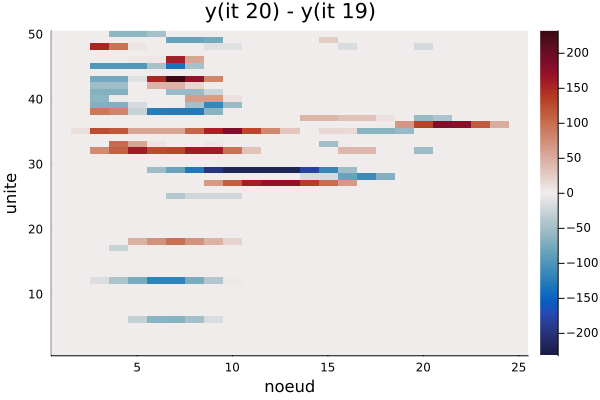

In [9]:
ITERATION = K    # iteration a examiner, comparee a la precedente
PASSE = 1        # passe avant de cette iteration (PASSES_PER_MIP passes par iteration)

actuel, avant = par_unite(ITERATION), par_unite(max(ITERATION - 1, 1))
texte(v) = isempty(v) ? "eteinte" : join(["[$a, $b]" for (a, b) in v], " ")

println("Intervalles de l'iteration $ITERATION ; * : unites qui different de l'iteration $(ITERATION - 1)\n")
for i in 1:instance.N
    isempty(actuel[i]) && isempty(avant[i]) && continue
    if actuel[i] == avant[i]
        println("   unite ", lpad(i, 3), " : ", texte(actuel[i]))
    else
        println(" * unite ", lpad(i, 3), " : ", texte(avant[i]), "  ->  ", texte(actuel[i]))
    end
end

y, y_avant = production(ITERATION, PASSE), production(max(ITERATION - 1, 1), PASSE)
zeta = reduce(hcat, states[ITERATION][PASSE].sampled_states_zeta)    # composantes de zeta x noeuds
dy = y .- y_avant

println("\nEtats echantillonnes de l'iteration $ITERATION (passe $PASSE) ; zeta (composantes x noeuds) :")
display(round.(zeta; digits = 4))
println("\nUnites dont la production y differe d'au moins 1e-6 de celle de l'iteration $(ITERATION - 1) :")
for i in findall(i -> maximum(abs, dy[i, :]) > 1e-6, 1:instance.N)
    n = argmax(abs.(dy[i, :]))
    @printf("   unite %3d : ecart max %8.3f au noeud %2d  (y = %.3f contre %.3f)\n", i, abs(dy[i, n]), n, y[i, n], y_avant[i, n])
end

m = max(maximum(abs, dy), 1e-9)
heatmap(dy; xlabel = "noeud", ylabel = "unite", color = :balance, clims = (-m, m),
        title = "y(it $ITERATION) - y(it $(ITERATION - 1))")

Unites dont y^k differe de y(gamma^k, ytilde^{k-1}) d'au moins 1e-6 (iteration 20, passe 1)
(l'intervalle est dit nouveau s'il n'etait pas choisi a l'iteration 19) :

   unite  17 : ecart max   27.413 au noeud  4  (y = 82.587 contre 110.000 ; intervalle deja choisi)
   unite  29 : ecart max   24.765 au noeud  3  (y = 156.078 contre 180.844 ; intervalle nouveau)
   unite  32 : ecart max  161.000 au noeud  5  (y = 212.000 contre 51.000 ; intervalle deja choisi)
   unite  33 : ecart max  102.178 au noeud  4  (y = 174.205 contre 72.028 ; intervalle deja choisi)
   unite  35 : ecart max  129.000 au noeud  5  (y = 57.000 contre 186.000 ; intervalle nouveau)
   unite  37 : ecart max   57.135 au noeud 20  (y = 146.865 contre 204.000 ; intervalle deja choisi)
   unite  38 : ecart max  129.000 au noeud  7  (y = 51.000 contre 180.000 ; intervalle deja choisi)
   unite  39 : ecart max  116.163 au noeud  9  (y = 71.561 contre 187.725 ; intervalle deja choisi)
   unite  40 : ecart max   62.906 au no

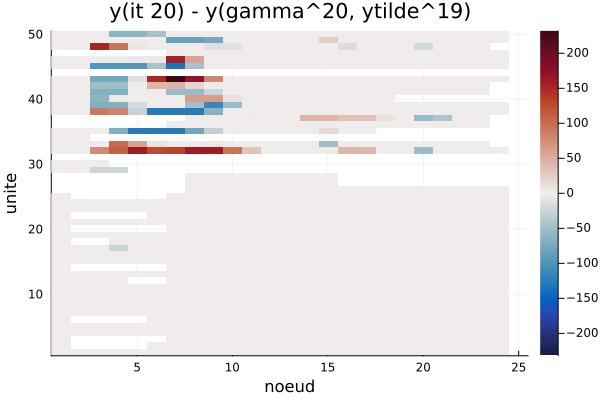

In [10]:
# y^k contre y(gamma^k, ytilde^{k-1}) a l'iteration ITERATION (definie dans la cellule precedente)
if METHOD != :extended || ITERATION < 2
    println("comparaison disponible en formulation intervalle, a partir de l'iteration 2")
else
    reel = production(ITERATION, PASSE)
    attendu, nouveau = y_gamma(ITERATION)
    ecart = reel .- attendu

    println("Unites dont y^k differe de y(gamma^k, ytilde^{k-1}) d'au moins 1e-6 (iteration $ITERATION, passe $PASSE)")
    println("(l'intervalle est dit nouveau s'il n'etait pas choisi a l'iteration $(ITERATION - 1)) :\n")
    for i in 1:instance.N
        valides = findall(!isnan, ecart[i, :])
        isempty(valides) && continue
        n = valides[argmax(abs.(ecart[i, valides]))]
        abs(ecart[i, n]) > 1e-6 || continue
        @printf("   unite %3d : ecart max %8.3f au noeud %2d  (y = %.3f contre %.3f ; intervalle %s)\n",
                i, abs(ecart[i, n]), n, reel[i, n], attendu[i, n], nouveau[i, n] ? "nouveau" : "deja choisi")
    end
    @printf("\n%d couples (unite, noeud) compares, dont %d avec un intervalle nouveau ; ecart max = %.3f\n",
            count(!isnan, ecart), count(nouveau), max_abs(ecart))

    m = max(max_abs(ecart), 1e-9)
    heatmap(ecart; xlabel = "noeud", ylabel = "unite", color = :balance, clims = (-m, m),
            title = "y(it $ITERATION) - y(gamma^$ITERATION, ytilde^$(ITERATION - 1))")
end

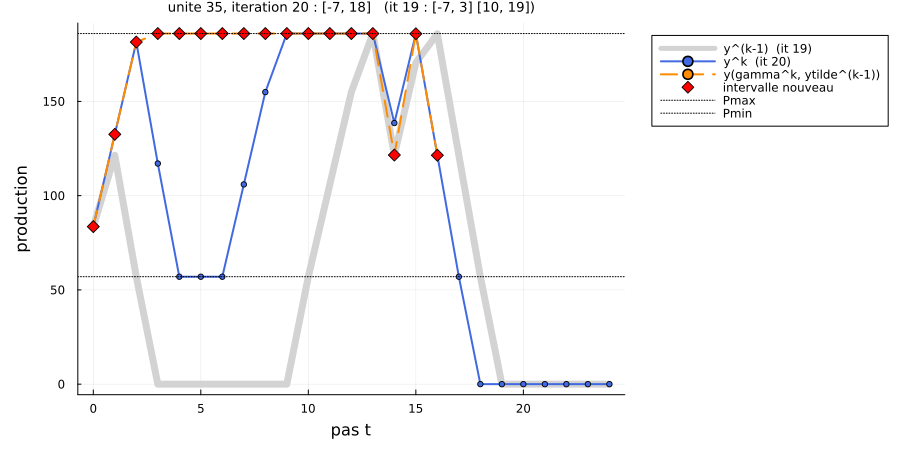

In [16]:
UNITE =  35   # unite a tracer ; l'iteration et la passe sont ITERATION et PASSE de la cellule de detail

# Trajectoires de la production de l'unite : y^k (iteration k), y^{k-1} (iteration k-1, derniere passe : celle dont
# les coupes sont les plus recentes) et y(gamma^k, ytilde^{k-1}). Losanges rouges : l'intervalle n'etait pas choisi
# a l'iteration k-1, ytilde vaut y (atteignable depuis un intervalle choisi) ou ybar ; les trous de la courbe orange sont les pas ou la coupe ne
# depend pas de y_t. Le pas t est celui du noeud n = t+1.
let
    unit, k = instance.Thermalunits[UNITE], ITERATION
    avant = max(k - 1, 1)
    y_k = production(k, PASSE)[UNITE, :]
    y_avant = production(avant, length(states[avant]))[UNITE, :]
    attendu, nouveau = METHOD == :extended && k >= 2 ? y_gamma(k) : (fill(NaN, instance.N, T + 1), falses(instance.N, T + 1))
    decrit(v) = isempty(v) ? "eteinte" : join(["[$a, $b]" for (a, b) in v], " ")

    p = plot(0:T, y_avant; label = "y^(k-1)  (it $avant)", color = :lightgray, linewidth = 7,
             xlabel = "pas t", ylabel = "production", legend = :outertopright, titlefontsize = 9, size = (900, 450),
             left_margin = 6Plots.mm, bottom_margin = 5Plots.mm,
             title = "unite $UNITE, iteration $k : $(decrit(par_unite(k)[UNITE]))   (it $avant : $(decrit(par_unite(avant)[UNITE])))")
    plot!(p, 0:T, y_k; label = "y^k  (it $k)", color = :royalblue, linewidth = 2, marker = :circle, markersize = 3)
    plot!(p, 0:T, attendu[UNITE, :]; label = "y(gamma^k, ytilde^(k-1))", color = :darkorange,
          linewidth = 2, linestyle = :dash, marker = :circle, markersize = 3)
    scatter!(p, 0:T, [nouveau[UNITE, n] ? attendu[UNITE, n] : NaN for n in 1:T+1];
             label = "intervalle nouveau", color = :red, marker = :diamond, markersize = 6)
    hline!(p, [unit.MaxPower]; label = "Pmax", color = :black, linestyle = :dot)
    hline!(p, [unit.MinPower]; label = "Pmin", color = :black, linestyle = :dot)
    p
end

iteration 20, passe 1 : coupe de l'iteration 19 (position 20). Ecart entre la somme des contributions et la
difference des valeurs de la coupe, au pire noeud : 1.06e-08

noeud  variation de la coupe   dont positive   dont negative
    2                  0.0             0.0             0.0
    3               -859.9          1066.1         -1926.0
    4            -111105.0           400.3       -111505.3
    5             -21268.8         17120.9        -38389.8
    6            -157914.3             6.2       -157920.5
    7            -168596.5            68.6       -168665.1
    8            -246661.9            73.6       -246735.5
    9            -237047.6          8636.3       -245683.9
   10             -61757.0             0.0        -61757.0
   11                  0.0             0.0             0.0
   12                  0.0             0.0             0.0
   13                  0.0             0.0             0.0
   14                245.2           245.2             0.0
  

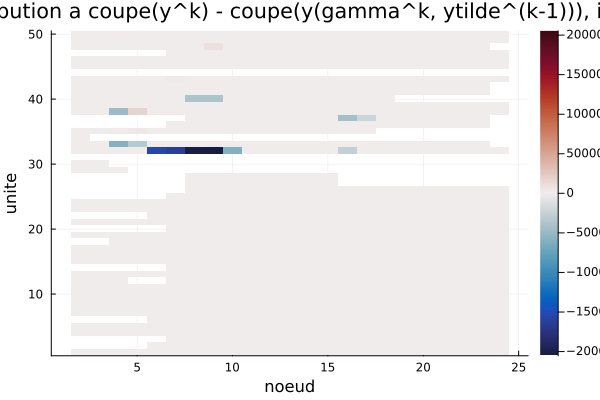

In [12]:
# Contribution de chaque unite a la variation de la valeur de la coupe de l'iteration k-1 quand l'etat visite y^k
# s'ecarte du point y(gamma^k, ytilde^{k-1}) ou elle a ete linearisee. La coupe est affine en y :
#     coupe(gamma, y) = alpha + delta.zeta + somme, sur les intervalles choisis, de (tau_id + beta_id y_unite),
# donc coupe(y^k) - coupe(y(gamma^k, ytilde^{k-1})) = somme_j beta_j (y^k_j - ytilde_j), et chaque terme est la
# contribution de l'unite j. Positive : la coupe est plus haute (futur plus cher) au point visite qu'au point de
# linearisation ; negative : plus basse. Signe de la pente beta_j : < 0, produire plus aujourd'hui fait baisser le
# cout futur (la montee en puissance est valorisee) ; = 0, branche limitee par la capacite ; > 0, produire coute.
# Le noeud n est l'etat y_t avec t = n-1 ; seuls les noeuds 2 a T portent une coupe d'etape.
if METHOD != :extended || ITERATION < 2
    println("disponible en formulation intervalle, a partir de l'iteration 2")
else
    k, unit = ITERATION, instance.Thermalunits[UNITE]
    I = instance.intervals
    reel = production(k, PASSE)
    attendu, nouveau = y_gamma(k)
    # coupe de la derniere passe de l'iteration k-1 : position 1 = coupe triviale, puis PASSES_PER_MIP par iteration
    position = 1 + (k - 1) * PASSES_PER_MIP

    # intervalle de gamma^k actif au noeud n (pas t+1 = n) pour chaque unite
    ident = zeros(Int, instance.N, T + 1)
    for id in schedules[k].selected, n in 1:T
        MSUC.is_on_interval(I.a[id], I.b[id], n) && (ident[I.unit[id], n] = id)
    end

    pente = fill(NaN, instance.N, T + 1)     # beta_j de la coupe
    contribution = fill(NaN, instance.N, T + 1)
    erreurs = Float64[]
    for n in 2:T
        cut = model[n].cuts[position]
        for i in 1:instance.N
            ident[i, n] == 0 && continue
            pente[i, n] = cut.beta[ident[i, n]]
            contribution[i, n] = pente[i, n] * (reel[i, n] - attendu[i, n])
        end
        # verification : somme des contributions = coupe(y^k) - coupe(y(gamma^k, ytilde^{k-1}))
        zeta = states[k][PASSE].sampled_states_zeta[n]
        valeur(y) = cut.alpha + sum(cut.delta .* zeta) +
                    sum(cut.beta[id] * y[I.unit[id]] + cut.tau[id] for id in schedules[k].selected)
        y_tilde = ifelse.(isnan.(attendu[:, n]), reel[:, n], attendu[:, n])
        push!(erreurs, abs(valeur(reel[:, n]) - valeur(y_tilde) - sum(filter(!isnan, contribution[:, n]); init = 0.0)))
    end
    @printf("iteration %d, passe %d : coupe de l'iteration %d (position %d). Ecart entre la somme des contributions et la\n", k, PASSE, k - 1, position)
    @printf("difference des valeurs de la coupe, au pire noeud : %.2e\n\n", maximum(erreurs))

    # par noeud : variation totale de la valeur de la coupe, et ses parts positive et negative
    println("noeud  variation de la coupe   dont positive   dont negative")
    for n in 2:T
        c = filter(!isnan, contribution[:, n])
        @printf("%5d %20.1f %15.1f %15.1f\n", n, sum(c; init = 0.0), sum(x -> max(x, 0.0), c; init = 0.0), sum(x -> min(x, 0.0), c; init = 0.0))
    end

    # par unite, sur tous les noeuds : les unites qui pesent le plus
    totaux = [sum(filter(!isnan, contribution[i, :]); init = 0.0) for i in 1:instance.N]
    absolus = [sum(abs, filter(!isnan, contribution[i, :]); init = 0.0) for i in 1:instance.N]
    println("\nunites qui contribuent le plus (somme sur les noeuds, et somme des valeurs absolues) :")
    for i in sortperm(absolus; rev = true)[1:min(10, instance.N)]
        @printf("   unite %3d : somme = %12.1f   somme des |.| = %12.1f\n", i, totaux[i], absolus[i])
    end

    # detail de l'unite UNITE
    println("\nunite $UNITE : Pmin = $(unit.MinPower), Pmax = $(unit.MaxPower), montee max R_up = $(unit.DeltaRampUp), descente max R_dn = $(unit.DeltaRampDown), cout lineaire = $(unit.LinearTerm)")
    println("noeud   y^k    y~^(k-1)   ecart    pente beta   contribution   montee y^k    intervalle")
    for n in 2:T
        id = ident[UNITE, n]
        id == 0 && continue
        @printf("%5d %7.1f %9.1f %8.1f %12.3f %13.1f %12.1f    [%d, %d] %s\n", n, reel[UNITE, n], attendu[UNITE, n], reel[UNITE, n] - attendu[UNITE, n],
                pente[UNITE, n], contribution[UNITE, n], reel[UNITE, n] - reel[UNITE, n-1], I.a[id], I.b[id], nouveau[UNITE, n] ? "(nouveau)" : "")
    end

    m = max(maximum(abs, filter(!isnan, contribution); init = 0.0), 1e-9)
    heatmap(contribution; xlabel = "noeud", ylabel = "unite", color = :balance, clims = (-m, m),
            title = "contribution a coupe(y^k) - coupe(y(gamma^k, ytilde^(k-1))), it $k")
end

### Temps de calcul par poste

Chronometres de `train` : racine (MIP), passe avant, passe arriere (resolution des LP, calcul des
coefficients des coupes, ajout des coupes) et mise a jour du planning.

In [13]:
MSUC.TimerOutputs.print_timer(stdout, model.timer_output; compact = true)

─────────────────────────────────────────────────────────────────────
                                          Time          Allocations  
                                    ───────────────   ───────────────
          Total measured:                40.6s            3.52GiB    

Section                     ncalls     time    %tot     alloc    %tot
─────────────────────────────────────────────────────────────────────
solve_first_stage_problem       20    18.2s   82.2%    264MiB   18.1%
forward_pass                    20    2.10s    9.5%    651MiB   44.6%
  solve_subproblem             480    2.00s    9.0%    640MiB   43.9%
  sample_scenario               20   62.4ms    0.3%   7.87MiB    0.5%
backward_pass                   20    1.13s    5.1%    380MiB   26.0%
  solve_subproblem             480    509ms    2.3%   89.1MiB    6.1%
    get_dual_solution          480    358ms    1.6%   72.5MiB    5.0%
  add_cut                      480    414ms    1.9%   88.4MiB    6.1%
  compute_coefficie

### Temps du MIP racine par iteration

Le probleme racine est un MIP resolu a chaque iteration : c'est en general le poste dominant de `train`.
Son temps croit avec le nombre de coupes accumulees ; l'option `MIP_GAP` (cellule des parametres) permet de l'accelerer.

MIP racine : 17.3 s au total, soit 77 % du temps d'entrainement (22.4 s)


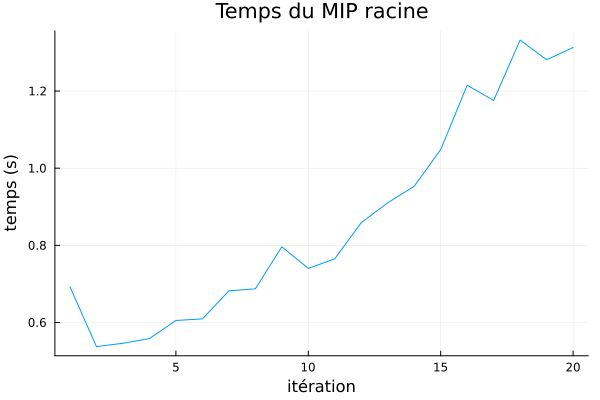

In [14]:
using Plots
t_mip = model[1].computation_time[1:length(log)]   # une resolution du MIP racine par iteration
@printf("MIP racine : %.1f s au total, soit %.0f %% du temps d'entrainement (%.1f s)\n",
        sum(t_mip), 100 * sum(t_mip) / log[end].time, log[end].time)
plot(t_mip, title = "Temps du MIP racine", xlabel = "itération", ylabel = "temps (s)", legend = false)